# Steam reviews — Xây dựng mô hình (TensorFlow / Keras)

Notebook này làm **3 bài toán** trên `data/steam_reviews_clean.csv` (đầu ra của `preprocessing.ipynb`, 9.971 review tiếng Anh):

| # | Bài toán | Đầu vào | Đầu ra | Loại mô hình |
|---|---|---|---|---|
| 1 | **Phân loại cảm xúc** (recommend hay không) | text + vài đặc trưng phụ | positive / negative | 3 mạng Keras + baseline sklearn |
| 2 | **Lọc review rác / đáng ngờ** | cờ chất lượng + dự đoán của mô hình 1 | điểm đáng ngờ, danh sách review cần xem | luật + mô hình 1 |
| 3 | **Chấm mức hữu ích** (review có được vote hữu ích không) | text + đặc trưng phụ + tuổi review | xác suất được vote | Keras + baseline sklearn |

**Cách đọc notebook**: mỗi phần có ô giải thích *làm gì – vì sao* trước code, và ô **Nhận xét** sau kết quả.
Phần cuối (§7) có bảng tổng hợp và các câu hỏi thầy có thể hỏi kèm gợi ý trả lời.

Thuật ngữ dùng nhiều:
- **Token**: một từ sau khi tách câu. **Vocabulary**: danh sách token mô hình biết.
- **Embedding**: mỗi token được biểu diễn bằng một vector số (vd 64 chiều) mà mô hình tự học trong lúc train.
- **Epoch**: một lượt mô hình đi qua toàn bộ tập train.
- **Accuracy**: tỉ lệ đoán đúng. **F1**: trung bình điều hoà giữa precision và recall.
  **ROC-AUC**: khả năng xếp review positive cao hơn negative (0,5 = đoán bừa, 1 = hoàn hảo).

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 0
tf.keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel("ERROR")
pd.set_option("display.max_colwidth", 150)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "không (chạy CPU)")

TensorFlow 2.20.0 | GPU: không (chạy CPU)


## 1. Đọc dữ liệu và tạo đặc trưng phụ (meta)
Ở `preprocessing.ipynb` §7 đã chốt: **text là tín hiệu chính**, các đặc trưng phụ chỉ bổ sung một ít. Đặc trưng phụ dùng:

| đặc trưng | ý nghĩa | vì sao dùng |
|---|---|---|
| `log_len` | log(số từ + 1) | review dài → nghiêng negative (ρ = −0,26) |
| `pt_*` (one-hot 5 khoảng giờ chơi) | < 2h, 2–10h, 10–50h, 50–200h, ≥ 200h | quan hệ giờ chơi–nhãn hình chữ ∩ nên chia khoảng thay vì dùng số |
| `has_score`, `score_x10` | review có ghi điểm "x/10" và điểm đó | rất mạnh nhưng hiếm (4,4%) |
| `has_question`, `has_censored` | có dấu "?" / có từ tục bị Steam che | đi cùng negative |

**Không dùng** `votes_helpful`, `timestamp_created` cho bài 1 vì chúng "lộ" nhãn do cách crawl (review cũ toàn negative,
xem `CLAUDE.md`). Hai cột này chỉ dùng ở bài 3.

In [2]:
df = pd.read_csv("data/steam_reviews_clean.csv")
df["text_clean"] = df.text_clean.astype(str)
print(df.shape, "| nhãn:", df.label.value_counts().to_dict(), "| số game:", df.app_id.nunique())

SCORE_RE = re.compile(r"(?<![\d/])(\d{1,2}(?:\.\d)?)\s*/\s*10\b")
def first_score(s):
    m = SCORE_RE.search(s)
    return float(m.group(1)) if m and float(m.group(1)) <= 10 else np.nan

PT_BINS = [-0.01, 2, 10, 50, 200, np.inf]
PT_LABELS = ["pt_lt2", "pt_2_10", "pt_10_50", "pt_50_200", "pt_ge200"]
df["log_len"] = np.log1p(df.word_count)
df["score_x10"] = df.text_clean.map(first_score)
df["has_score"] = df.score_x10.notna().astype(int)
df["score_x10"] = df.score_x10.fillna(0)
df["has_question"] = df.text_clean.str.contains("?", regex=False).astype(int)
df["has_censored"] = df.has_censored.astype(int)
df = pd.concat([df, pd.get_dummies(pd.cut(df.playtime_forever_hours, PT_BINS, labels=PT_LABELS)).astype(int)], axis=1)

META = ["log_len", "has_score", "score_x10", "has_question", "has_censored"] + PT_LABELS
display(df[["text_clean", "label"] + META].head())

(9971, 19) | nhãn: {1: 5000, 0: 4971} | số game: 99


,text_clean,label,log_len,has_score,score_x10,has_question,has_censored,pt_lt2,pt_2_10,pt_10_50,pt_50_200,pt_ge200
0,"its hard at first, but fun later.",1,2.079442,0,0.0,0,0,0,0,1,0,0
1,IT'S MY FAV GAME TO PLAY <3,1,2.079442,0,0.0,0,0,0,0,0,0,1
2,"nice game i just found out i have an sever gamble addiction and hate france,i spend 45 dollars on this game and didnt got a single good thing i wo...",1,3.555348,1,10.0,0,0,0,0,1,0,0
3,I think these guys can see me through the walls,1,2.397895,0,0.0,0,0,0,0,0,0,1
4,I LOVE THIS GAME SO MATCH BUT THE HACKERS ARE A LOT IN THIS GAME,1,2.772589,0,0.0,0,0,0,0,1,0,0


## 2. Chia dữ liệu: 2 kịch bản đánh giá
- **Kịch bản A — game đã biết**: chia ngẫu nhiên 70% train / 15% validation / 15% test, giữ tỉ lệ nhãn (stratified).
  Test có review của cùng các game đã có trong train.
- **Kịch bản B — game mới**: chọn ngẫu nhiên 20% **số game** làm test, review của các game đó không xuất hiện khi train
  (chia theo nhóm = game). Kịch bản này kiểm tra mô hình có học **cách người chơi khen/chê** hay chỉ học thuộc từ riêng
  của từng game (tên nhân vật, tên map…). Đây là kịch bản sát thực tế hơn khi áp mô hình cho game khác.

**Validation** dùng để chọn tham số và dừng train sớm (early stopping); **test** chỉ dùng một lần ở cuối để báo cáo.

In [3]:
idx = np.arange(len(df))
trA, teA = train_test_split(idx, test_size=.15, stratify=df.label, random_state=SEED)
trA, vaA = train_test_split(trA, test_size=.15 / .85, stratify=df.label.iloc[trA], random_state=SEED)

gss = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED)
trB, teB = next(gss.split(idx, groups=df.app_id))
trB, vaB = train_test_split(trB, test_size=.15, stratify=df.label.iloc[trB], random_state=SEED)

SPLITS = {"A": (trA, vaA, teA), "B": (trB, vaB, teB)}
rows = []
for k, (tr, va, te) in SPLITS.items():
    for name, ix in [("train", tr), ("val", va), ("test", te)]:
        rows.append({"kịch bản": k, "tập": name, "n": len(ix), "% positive": round(df.label.iloc[ix].mean() * 100, 1),
                     "số game": df.app_id.iloc[ix].nunique()})
display(pd.DataFrame(rows))
print("Kịch bản B — game trong test không có trong train:",
      len(set(df.app_id.iloc[teB]) & set(df.app_id.iloc[trB])) == 0)

,kịch bản,tập,n,% positive,số game
0,A,train,6979,50.2,99
1,A,val,1496,50.1,99
2,A,test,1496,50.1,99
3,B,train,6813,50.0,79
4,B,val,1203,50.0,79
5,B,test,1955,50.7,20


Kịch bản B — game trong test không có trong train: True


In [4]:
RESULTS = []

def evaluate(name, scenario, y_true, p, task="sentiment"):
    """Tính metric từ xác suất p (ngưỡng 0,5) và lưu vào bảng kết quả chung."""
    yhat = (p >= .5).astype(int)
    r = {"bài": task, "mô hình": name, "kịch bản": scenario,
         "accuracy": accuracy_score(y_true, yhat), "F1": f1_score(y_true, yhat),
         "ROC-AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p)}
    RESULTS.append(r)
    return r

def show_results(task):
    t = pd.DataFrame([r for r in RESULTS if r["bài"] == task]).drop(columns="bài")
    display(t.pivot_table(index="mô hình", columns="kịch bản", values=["accuracy", "F1", "ROC-AUC"], sort=False).round(3))

## 3. Bài 1 — Phân loại cảm xúc

### 3.1 Baseline (sklearn)
Trước khi dùng mạng neural, cần **mốc so sánh** đơn giản để biết mạng neural có thực sự tốt hơn không.
- **Chỉ meta**: Logistic Regression trên 10 đặc trưng phụ → biết phần thông tin nằm ngoài text.
- **TF-IDF + LR**: biến text thành vector đếm từ có trọng số (từ hiếm và đặc trưng được trọng số cao), dùng cả
  cụm 1–2 từ (*not good*) và cụm ký tự 3–5 (bắt lỗi chính tả, từ dính nhau). Đây là baseline rất mạnh cho text ngắn.
- **TF-IDF + meta + LR**: ghép thêm đặc trưng phụ.

Tham số `C` (độ mạnh regularization) chọn trên tập validation.

In [5]:
def tfidf_features(tr, others):
    w = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)
    c = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=80000, sublinear_tf=True)
    txt = df.text_clean.values
    Xtr = hstack([w.fit_transform(txt[tr]), c.fit_transform(txt[tr])]).tocsr()
    return Xtr, [hstack([w.transform(txt[ix]), c.transform(txt[ix])]).tocsr() for ix in others]

def fit_lr(Xtr, ytr, Xva, yva, Cs=(.25, .5, 1, 2, 4, 8)):
    best = max(((roc_auc_score(yva, LogisticRegression(C=C, max_iter=3000).fit(Xtr, ytr).predict_proba(Xva)[:, 1]), C)
                for C in Cs))
    return LogisticRegression(C=best[1], max_iter=3000).fit(Xtr, ytr), best[1]

y = df.label.values
LR_PRED = {}
for k, (tr, va, te) in SPLITS.items():
    sc = StandardScaler().fit(df[META].values[tr])
    M = {n: sc.transform(df[META].values[ix]) for n, ix in [("tr", tr), ("va", va), ("te", te)]}
    m, C = fit_lr(M["tr"], y[tr], M["va"], y[va])
    evaluate("LR — chỉ meta", k, y[te], m.predict_proba(M["te"])[:, 1])

    Ttr, (Tva, Tte) = tfidf_features(tr, [va, te])
    m, C = fit_lr(Ttr, y[tr], Tva, y[va])
    evaluate("TF-IDF + LR", k, y[te], m.predict_proba(Tte)[:, 1])

    Xtr, Xva, Xte = (hstack([T, csr_matrix(M[n])]).tocsr() for T, n in [(Ttr, "tr"), (Tva, "va"), (Tte, "te")])
    m, C = fit_lr(Xtr, y[tr], Xva, y[va])
    LR_PRED[k] = m.predict_proba(Xte)[:, 1]
    evaluate("TF-IDF + meta + LR", k, y[te], LR_PRED[k])
    print(f"Kịch bản {k}: C tốt nhất cho TF-IDF + meta = {C}")
show_results("sentiment")

Kịch bản A: C tốt nhất cho TF-IDF + meta = 2


Kịch bản B: C tốt nhất cho TF-IDF + meta = 2


accuracy            F1        ROC-AUC       
kịch bản                  A      B      A      B       A      B
mô hình                                                        
LR — chỉ meta         0.661  0.657  0.691  0.688   0.716  0.711
TF-IDF + LR           0.818  0.827  0.815  0.827   0.903  0.906
TF-IDF + meta + LR    0.825  0.836  0.823  0.838   0.908  0.909

**Nhận xét (baseline)**
- **Chỉ meta** đạt ROC-AUC ≈ 0,71: đặc trưng phụ có tín hiệu nhưng yếu, đúng như EDA.
- **TF-IDF + LR** nhảy lên ≈ 0,90: thông tin nằm chủ yếu trong **text**.
- Thêm meta cải thiện nhẹ (+0,005 ROC-AUC, +1% accuracy) → meta bổ sung được chút ít ngoài text (giờ chơi, điểm x/10).
- Kịch bản B (game mới) **không tệ hơn** kịch bản A → mô hình học cách khen/chê chung, không phụ thuộc từng game.

### 3.2 Chuẩn bị text cho Keras: `TextVectorization`
Mạng neural không đọc chữ trực tiếp. Lớp `TextVectorization` của Keras:
1. chuyển chữ thường, bỏ dấu câu;
2. tách thành token, giữ **20.000 token** phổ biến nhất (token lạ → mã `[UNK]`);
3. đổi mỗi review thành dãy số nguyên độ dài cố định **`MAX_LEN = 256`**: review ngắn hơn được đệm số 0 (*padding*),
   dài hơn bị cắt. 256 token bao phủ ≈ 96% review (95% review có ≤ 208 từ).

Lớp này chỉ học vocabulary từ **tập train** để không "nhìn trộm" test.

In [6]:
VOCAB, MAX_LEN, TFIDF_VOCAB = 20000, 256, 30000

def make_vectorizer(tr, mode="int"):
    """mode="int": dãy mã token (cho Embedding). mode="tf_idf": vector TF-IDF cụm 1–2 từ (cho mạng M4)."""
    if mode == "int":
        v = tf.keras.layers.TextVectorization(max_tokens=VOCAB, output_sequence_length=MAX_LEN)
    else:
        v = tf.keras.layers.TextVectorization(max_tokens=TFIDF_VOCAB, ngrams=2, output_mode="tf_idf")
    v.adapt(tf.constant(df.text_clean.values[tr].tolist()))
    return v

vecA = make_vectorizer(trA)
vocab = vecA.get_vocabulary()
print("Kích thước vocabulary:", len(vocab), "| 15 token đầu:", [str(t) for t in vocab[:15]])
ex = df.text_clean.iloc[trA[0]]
print("\nVí dụ:", ex[:120])
print("→ dãy số:", vecA([ex]).numpy()[0][:25], "...")

Kích thước vocabulary: 19346 | 15 token đầu: ['', '[UNK]', 'the', 'and', 'to', 'game', 'a', 'i', 'is', 'of', 'it', 'you', 'this', 'in', 'for']

Ví dụ: Have you ever wanted to play a game that has the following? *Lobotomization *Semi-legal organ harvesting *Evil ass shado
→ dãy số: [   20    11   106   372     4    28     6     5    15    52     2  1489
 14225 11811  8040  5420  1257   311  3579  4785    15   171    11 15497
     3] ...


### 3.3 Ba kiến trúc mạng (theo các lab của môn)
Cả 3 mạng đều có **2 nhánh đầu vào** (Keras functional API):
- **Nhánh text**: dãy token → `Embedding` (mỗi token thành vector 64 chiều) → lớp xử lý chuỗi (khác nhau giữa 3 mạng)
  → vector tóm tắt cả review.
- **Nhánh meta**: 10 đặc trưng phụ → chuẩn hoá (`Normalization`) → `Dense`.
- Hai nhánh **nối lại** (`Concatenate`) → `Dense` → `Dropout` (tắt ngẫu nhiên 40% nơ-ron khi train để chống overfit)
  → 1 nơ-ron `sigmoid` cho xác suất positive.

| mạng | lớp xử lý chuỗi | ý tưởng | lab tương ứng |
|---|---|---|---|
| **M1 — Embedding + Pooling** | `GlobalAveragePooling1D` | lấy trung bình vector các từ, không quan tâm thứ tự ("túi từ" học được) | 3.1–3.5 |
| **M2 — BiLSTM** | `Bidirectional(LSTM(64))` | đọc chuỗi theo 2 chiều, nhớ ngữ cảnh/thứ tự (vd *"not bad at all"*) | 3.2 |
| **M3 — CNN 1D** | `Conv1D(128, 5)` + `GlobalMaxPooling1D` | quét cửa sổ 5 từ, bắt các cụm từ mạnh ở bất kỳ vị trí nào | 3.3 |
| **M4 — TF-IDF + Dense** | `TextVectorization(output_mode="tf_idf", ngrams=2)` → `Dense(32)` | không học embedding; dùng trực tiếp vector TF-IDF cụm 1–2 từ (30.000 chiều) như baseline sklearn nhưng bằng mạng neural | 3.1–3.3 |

M4 được thêm vì baseline TF-IDF + LR rất mạnh trên dữ liệu ~10k review: mạng học embedding từ đầu (M1–M3) cần nhiều
dữ liệu hơn mới vượt được. M4 kiểm tra một mạng neural dùng cùng kiểu biểu diễn đó.

Train bằng `Adam`, loss `binary_crossentropy`, **EarlyStopping**: dừng khi `val_loss` không giảm sau 2 epoch
và lấy lại trọng số tốt nhất.

In [7]:
EMB = 64

def build_model(kind, vectorizer, n_meta, meta_train, use_meta=True, name=None):
    txt_in = tf.keras.Input(shape=(), dtype=tf.string, name="text")
    x = vectorizer(txt_in)
    if kind != "tfidf":
        x = tf.keras.layers.Embedding(VOCAB, EMB, mask_zero=(kind == "bilstm"), name="embedding")(x)
    if kind == "tfidf":
        x = tf.keras.layers.Dropout(.5)(x)
        x = tf.keras.layers.Dense(32, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    elif kind == "pool":
        x = tf.keras.layers.GlobalAveragePooling1D()(x)
    elif kind == "bilstm":
        x = tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64))(x)
    elif kind == "cnn":
        x = tf.keras.layers.Conv1D(128, 5, activation="relu")(x)
        x = tf.keras.layers.GlobalMaxPooling1D()(x)
    inputs = [txt_in]
    if use_meta:
        meta_in = tf.keras.Input(shape=(n_meta,), name="meta")
        norm = tf.keras.layers.Normalization()
        norm.adapt(meta_train)
        m = tf.keras.layers.Dense(16, activation="relu")(norm(meta_in))
        x = tf.keras.layers.Concatenate()([x, m])
        inputs.append(meta_in)
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    x = tf.keras.layers.Dropout(.4)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    model = tf.keras.Model(inputs, out, name=name or kind)
    lr = {"tfidf": 3e-4}.get(kind, 1e-3)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model

def to_inputs(ix, meta_cols, use_meta=True):
    d = {"text": tf.constant(df.text_clean.values[ix].tolist())}
    if use_meta:
        d["meta"] = df[meta_cols].values[ix].astype("float32")
    return d

def train(model, tr, va, target, meta_cols, use_meta=True, epochs=None, class_weight=None):
    # M1 học chậm (chỉ lấy trung bình) nên cho tối đa 30 epoch; các mạng khác 15 epoch là đủ (EarlyStopping dừng sớm)
    epochs = epochs or (30 if "Pooling" in model.name else 15)
    t0 = time.time()
    h = model.fit(to_inputs(tr, meta_cols, use_meta), target[tr],
                  validation_data=(to_inputs(va, meta_cols, use_meta), target[va]),
                  epochs=epochs, batch_size=64, verbose=0, class_weight=class_weight,
                  callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)])
    print(f"{model.name}: {len(h.history['loss'])} epoch, {time.time() - t0:.0f}s, "
          f"val_loss tốt nhất {min(h.history['val_loss']):.3f}")
    return h

def predict(model, ix, meta_cols, use_meta=True):
    return model.predict(to_inputs(ix, meta_cols, use_meta), verbose=0, batch_size=256).ravel()

In [8]:
model_m2 = build_model("bilstm", vecA, len(META), df[META].values[trA].astype("float32"), name="M2_BiLSTM")
model_m2.summary()

Model: "M2_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 256)       │          0 │ text[0][0]        │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meta (InputLayer)   │ (None, 10)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 256, 64)   │  1,280,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 256)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 10)        │         21 │ meta[0][0]        │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     66,048 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │        176 │ normalization[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 144)       │          0 │ bidirectional[0]… │
│ (Concatenate)       │                   │            │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      4,640 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,350,918 (5.15 MB)

 Trainable params: 1,350,897 (5.15 MB)

 Non-trainable params: 21 (88.00 B)

Bảng `summary` cho thấy từng lớp, kích thước đầu ra và số tham số. Phần lớn tham số nằm ở lớp `Embedding`
(20.000 token × 64 chiều = 1,28 triệu).

### 3.4 Train và đánh giá — kịch bản A

In [9]:
KERAS = [("M1 Embedding+Pooling", "pool", True), ("M2 BiLSTM", "bilstm", True), ("M3 CNN 1D", "cnn", True),
         ("M4 TF-IDF+Dense", "tfidf", True), ("M2 BiLSTM — chỉ text", "bilstm", False)]
vecA_tfidf = make_vectorizer(trA, "tf_idf")
HIST, PRED_A, MODELS_A = {}, {}, {}
tr, va, te = SPLITS["A"]
for label, kind, use_meta in KERAS:
    tf.keras.utils.set_random_seed(SEED)
    m = build_model(kind, vecA_tfidf if kind == "tfidf" else vecA, len(META), df[META].values[tr].astype("float32"),
                    use_meta, name=re.sub(r"[^A-Za-z0-9]+", "_", label))
    HIST[label] = train(m, tr, va, y, META, use_meta)
    PRED_A[label] = predict(m, te, META, use_meta)
    MODELS_A[label] = m
    evaluate(label, "A", y[te], PRED_A[label])

M1_Embedding_Pooling: 12 epoch, 27s, val_loss tốt nhất 0.504


M2_BiLSTM: 3 epoch, 61s, val_loss tốt nhất 0.408


M3_CNN_1D: 4 epoch, 20s, val_loss tốt nhất 0.421


M4_TF_IDF_Dense: 6 epoch, 21s, val_loss tốt nhất 0.433


M2_BiLSTM_ch_text: 4 epoch, 75s, val_loss tốt nhất 0.407


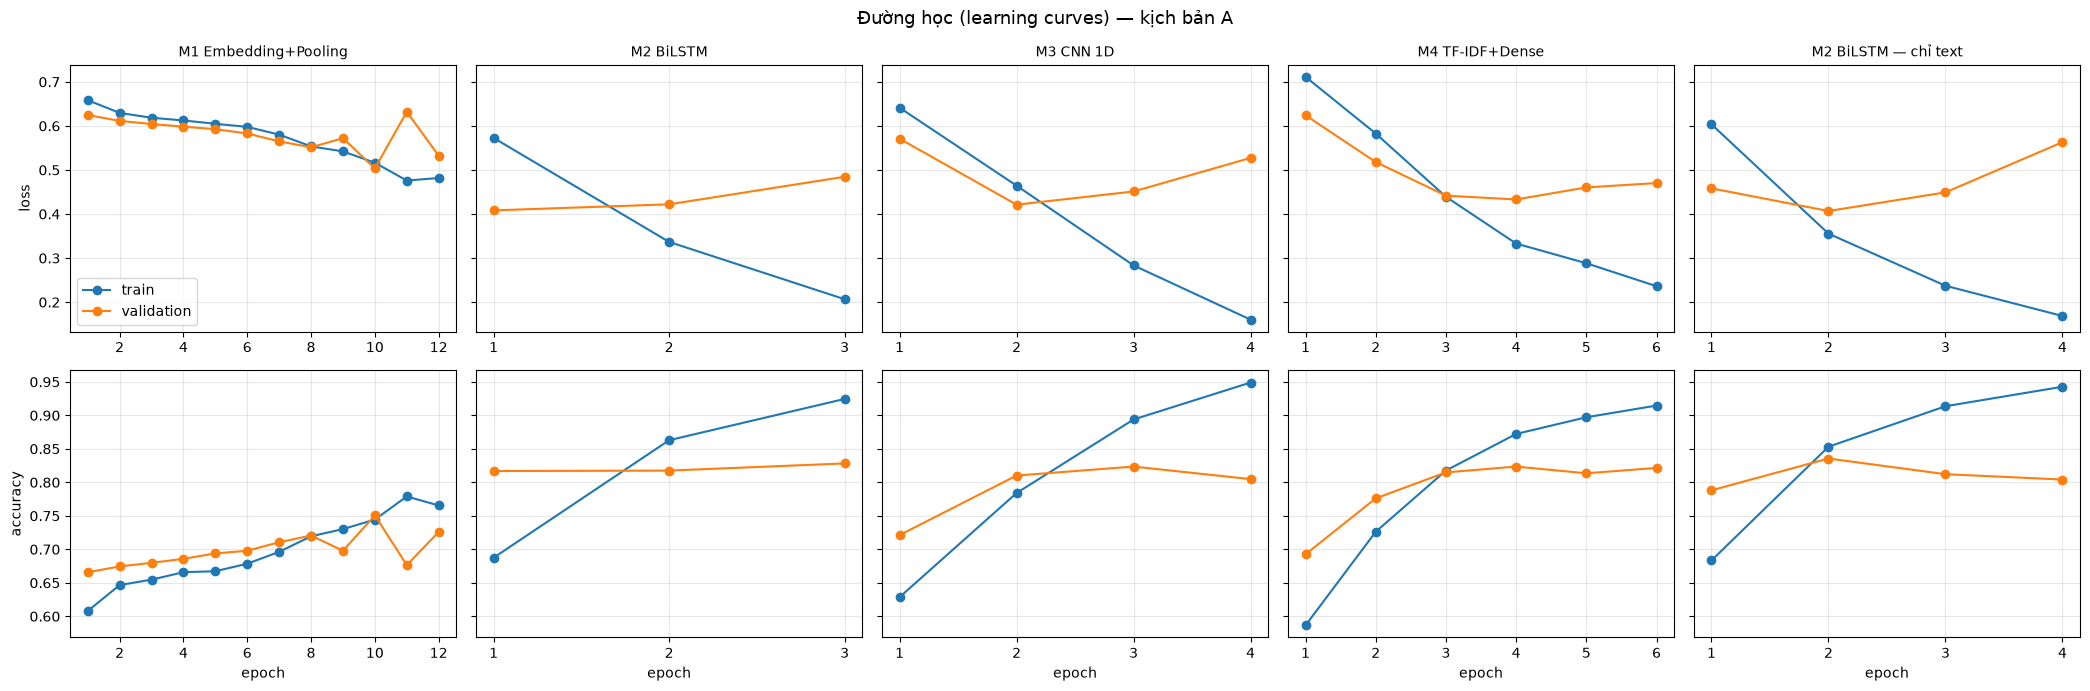

In [10]:
fig, axes = plt.subplots(2, len(HIST), figsize=(4.2 * len(HIST), 7), sharey="row")
for j, (label, h) in enumerate(HIST.items()):
    ep = np.arange(1, len(h.history["loss"]) + 1)
    axes[0, j].plot(ep, h.history["loss"], "o-", label="train")
    axes[0, j].plot(ep, h.history["val_loss"], "o-", label="validation")
    axes[0, j].set_title(label, fontsize=10)
    axes[1, j].plot(ep, h.history["accuracy"], "o-", label="train")
    axes[1, j].plot(ep, h.history["val_accuracy"], "o-", label="validation")
    axes[1, j].set_xlabel("epoch")
    for a in axes[:, j]:
        a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0, 0].set_ylabel("loss"); axes[1, 0].set_ylabel("accuracy"); axes[0, 0].legend()
fig.suptitle("Đường học (learning curves) — kịch bản A", fontsize=13)
fig.tight_layout()
plt.show()

**Cách đọc đường học**: loss train giảm liên tục trong khi loss validation giảm rồi **đi ngang/tăng lại** là dấu hiệu
**overfitting** (mô hình bắt đầu học thuộc tập train). EarlyStopping dừng ở đó và lấy trọng số tại epoch có
val_loss thấp nhất.

### 3.5 Kịch bản B — game mới
Train lại các mô hình trên tập train của kịch bản B (vocabulary cũng học lại chỉ từ các game train).

In [11]:
tr, va, te = SPLITS["B"]
vecB, vecB_tfidf = make_vectorizer(tr), make_vectorizer(tr, "tf_idf")
PRED_B = {}
for label, kind, use_meta in KERAS:
    tf.keras.utils.set_random_seed(SEED)
    m = build_model(kind, vecB_tfidf if kind == "tfidf" else vecB, len(META), df[META].values[tr].astype("float32"), use_meta,
                    name=re.sub(r"[^A-Za-z0-9]+", "_", label) + "_B")
    train(m, tr, va, y, META, use_meta)
    PRED_B[label] = predict(m, te, META, use_meta)
    evaluate(label, "B", y[te], PRED_B[label])
show_results("sentiment")

M1_Embedding_Pooling_B: 18 epoch, 37s, val_loss tốt nhất 0.422


M2_BiLSTM_B: 4 epoch, 78s, val_loss tốt nhất 0.438


M3_CNN_1D_B: 4 epoch, 20s, val_loss tốt nhất 0.450


M4_TF_IDF_Dense_B: 7 epoch, 26s, val_loss tốt nhất 0.451


M2_BiLSTM_ch_text_B: 3 epoch, 56s, val_loss tốt nhất 0.432


accuracy            F1        ROC-AUC       
kịch bản                    A      B      A      B       A      B
mô hình                                                          
LR — chỉ meta           0.661  0.657  0.691  0.688   0.716  0.711
TF-IDF + LR             0.818  0.827  0.815  0.827   0.903  0.906
TF-IDF + meta + LR      0.825  0.836  0.823  0.838   0.908  0.909
M1 Embedding+Pooling    0.741  0.801  0.774  0.810   0.836  0.883
M2 BiLSTM               0.801  0.799  0.799  0.787   0.884  0.893
M3 CNN 1D               0.797  0.794  0.801  0.792   0.871  0.883
M4 TF-IDF+Dense         0.812  0.815  0.823  0.817   0.891  0.893
M2 BiLSTM — chỉ text    0.799  0.802  0.791  0.788   0.889  0.882

### 3.6 Kết hợp mô hình (ensemble)
Các mạng nhìn text theo cách khác nhau: M2 đọc theo thứ tự từ, M4 nhìn cụm từ (TF-IDF). Lấy **trung bình xác suất**
của M2 BiLSTM và M4 thường cho kết quả ổn định hơn từng mạng riêng lẻ, vì lỗi của hai mạng không trùng nhau hoàn toàn.

In [12]:
ENS = ["M2 BiLSTM", "M4 TF-IDF+Dense"]
for k, P in [("A", PRED_A), ("B", PRED_B)]:
    P["M5 Ensemble (M2 + M4)"] = np.mean([P[n] for n in ENS], axis=0)
    evaluate("M5 Ensemble (M2 + M4)", k, y[SPLITS[k][2]], P["M5 Ensemble (M2 + M4)"])
print("Tương quan dự đoán M2 và M4 (kịch bản A):", round(np.corrcoef(PRED_A[ENS[0]], PRED_A[ENS[1]])[0, 1], 3))
show_results("sentiment")

Tương quan dự đoán M2 và M4 (kịch bản A): 0.853


accuracy            F1        ROC-AUC       
kịch bản                     A      B      A      B       A      B
mô hình                                                           
LR — chỉ meta            0.661  0.657  0.691  0.688   0.716  0.711
TF-IDF + LR              0.818  0.827  0.815  0.827   0.903  0.906
TF-IDF + meta + LR       0.825  0.836  0.823  0.838   0.908  0.909
M1 Embedding+Pooling     0.741  0.801  0.774  0.810   0.836  0.883
M2 BiLSTM                0.801  0.799  0.799  0.787   0.884  0.893
M3 CNN 1D                0.797  0.794  0.801  0.792   0.871  0.883
M4 TF-IDF+Dense          0.812  0.815  0.823  0.817   0.891  0.893
M2 BiLSTM — chỉ text     0.799  0.802  0.791  0.788   0.889  0.882
M5 Ensemble (M2 + M4)    0.824  0.826  0.830  0.822   0.902  0.905

**Nhận xét (so sánh các mạng Keras)**

| mạng | ROC-AUC A | ROC-AUC B | nhận xét |
|---|---|---|---|
| M1 Pooling | 0,84 | 0,88 | đơn giản nhất, học chậm (12–18 epoch), kém nhất |
| M2 BiLSTM | 0,88 | 0,89 | hiểu thứ tự từ, nhưng chậm nhất (≈ 60–80 s) và overfit sau 1–2 epoch |
| M3 CNN | 0,87 | 0,88 | nhanh, ngang M2 |
| **M4 TF-IDF + Dense** | **0,89** | **0,89** | mạng đơn tốt nhất, nhanh |
| M2 chỉ text | 0,89 | 0,88 | gần bằng M2 có meta → mạng tự học được phần lớn tín hiệu meta (vd độ dài) từ text |
| **M5 Ensemble M2 + M4** | **0,90** | **0,91** | tốt nhất trong các mô hình TensorFlow, ngang baseline TF-IDF + LR |

- **Vì sao mạng neural không vượt hẳn Logistic Regression?** Dữ liệu chỉ ~7.000 review train, mà M1–M3 phải tự học
  embedding cho 20.000 từ từ con số 0 (1,28 triệu tham số) → dễ overfit (đường học: loss train giảm mạnh, val_loss tăng
  từ epoch 2–3). TF-IDF + LR có ít "tự do" hơn nên ổn định hơn trên dữ liệu nhỏ. Đây là kết quả thường gặp; muốn vượt
  rõ cần dữ liệu lớn hơn hoặc embedding/mô hình **đã train sẵn** (GloVe, BERT).
- Ensemble tốt hơn từng mạng vì dự đoán của M2 và M4 tương quan 0,85 chứ không trùng hẳn: chỗ M2 sai, M4 đôi khi đúng.
- Kịch bản B ≈ kịch bản A ở mọi mạng → mô hình **khái quát được sang game chưa thấy**.

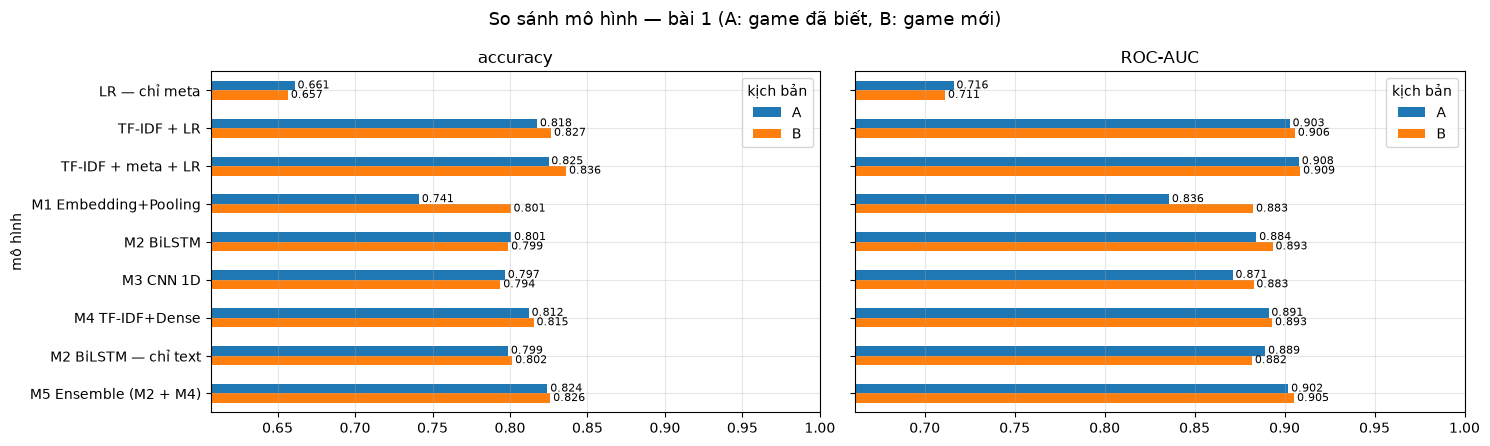

In [13]:
res = pd.DataFrame([r for r in RESULTS if r["bài"] == "sentiment"])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, metric in zip(axes, ["accuracy", "ROC-AUC"]):
    p = res.pivot_table(index="mô hình", columns="kịch bản", values=metric, sort=False)
    p.plot.barh(ax=ax, color=["C0", "C1"])
    ax.set_xlim(max(.5, p.values.min() - .05), 1)
    ax.set_title(metric)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
axes[0].invert_yaxis()
fig.suptitle("So sánh mô hình — bài 1 (A: game đã biết, B: game mới)", fontsize=13)
fig.tight_layout()
plt.show()

### 3.7 Phân tích lỗi của mạng Keras đơn tốt nhất (kịch bản A)

Mạng Keras tốt nhất (ROC-AUC, kịch bản A): M4 TF-IDF+Dense


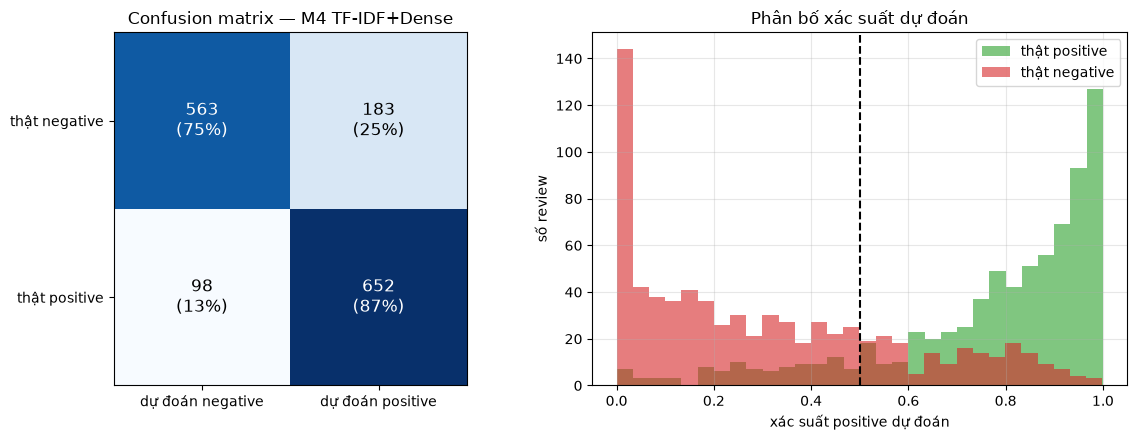

Số review đoán sai: 281 / 1496

Sai tự tin nhất — thật negative nhưng mô hình chắc là positive:


,game_name,text_clean,p_pos
8973,Crimson Desert Enhanced,"Lots of very wide systems, but nothing of substance long term. Skip unless you really have a ton of time to burn. Most of the content is in the fi...",0.999
4410,R.E.P.O.,Friend-slop which didn't pass through time. High online&hype on release after 3-6 month game is basically dead. Still on early access still no maj...,0.994
4386,R.E.P.O.,Its a fun game to play every now and then but gets a little boring after a while. Messing with your friends inside the store room is almost 70% of...,0.976
7501,Age of Empires II: Definitive Edition,I never complain about a game that is too hard but the learning curve is so steep for this game that I honestly don't have the time of my life for...,0.952
1997,Delta Force,"Everything you hate about what COD has become, is what this game actively tries to be. Adding strange futuristic fantasy elements and cringey char...",0.950
4093,Monster Hunter Wilds,"It took 8.9 hours to give up on Wilds. I came in wanting to adore this game as I have for every game in the series I've played, 3U, GU, World, Ris...",0.948


Sai tự tin nhất — thật positive nhưng mô hình chắc là negative:


,game_name,text_clean,p_pos
1565,The Binding of Isaac: Rebirth,---{ Graphics }--- ☐ You forget what reality is ☐ Beautiful ☐ Good ☐ Decent ☐ Bad ☑ Don't look too long at it ☐ MS-DOS ---{ Gameplay }--- ☑ Very g...,0.000
5252,ARC Raiders,I just killed an innocent man. I thought it would be fun to be a rat for once. I befriended him at the start of the raid. I gave him some good loo...,0.000
1776,Dead by Daylight,"today i have officially stopped playing Dead by Daylight. i was happy playing dracula for a while since he is such a fun character, but for some r...",0.001
3275,VRChat,"okay, a local fur of VRC here, sweet lord ever since Rec Room's unfortunate demise the children (and i actually mean <13 y. o.) have come into ins...",0.005
9952,Dota 2,You can talk about Dota for a very long time. The most important thing you should know: 1. It is precisely thanks to Dota that you will finally be...,0.008
7052,Wuthering Waves,"This game has a lot of pretty chars (yes, I love looking at pretty chars) but they are only side dishes for me. I'm a casual player and when it go...",0.009


In [14]:
resA = res[res["kịch bản"] == "A"].set_index("mô hình")
best_keras = resA.loc[[k for k, *_ in KERAS], "ROC-AUC"].idxmax()
print("Mạng Keras tốt nhất (ROC-AUC, kịch bản A):", best_keras)
tr, va, te = SPLITS["A"]
p_best = PRED_A[best_keras]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cm = confusion_matrix(y[te], (p_best >= .5).astype(int))
axes[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%})", ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
axes[0].set_xticks([0, 1], ["dự đoán negative", "dự đoán positive"])
axes[0].set_yticks([0, 1], ["thật negative", "thật positive"])
axes[0].grid(False)
axes[0].set_title(f"Confusion matrix — {best_keras}")

axes[1].hist(p_best[y[te] == 1], bins=30, alpha=.6, label="thật positive", color="C2")
axes[1].hist(p_best[y[te] == 0], bins=30, alpha=.6, label="thật negative", color="C3")
axes[1].axvline(.5, c="k", ls="--")
axes[1].set(xlabel="xác suất positive dự đoán", ylabel="số review", title="Phân bố xác suất dự đoán")
axes[1].legend()
fig.tight_layout()
plt.show()

err = df.iloc[te][["game_name", "text_clean", "label", "playtime_forever_hours"]].assign(p_pos=p_best.round(3))
err["sai"] = (err.p_pos >= .5).astype(int) != err.label
print(f"Số review đoán sai: {err.sai.sum()} / {len(err)}")
print("\nSai tự tin nhất — thật negative nhưng mô hình chắc là positive:")
display(err[(err.label == 0)].nlargest(6, "p_pos")[["game_name", "text_clean", "p_pos"]])
print("Sai tự tin nhất — thật positive nhưng mô hình chắc là negative:")
display(err[(err.label == 1)].nsmallest(6, "p_pos")[["game_name", "text_clean", "p_pos"]])

In [15]:
# Độ chính xác theo độ dài review
err["len_bin"] = pd.cut(df.word_count.iloc[te].values, [0, 5, 10, 20, 50, 100, 10000],
                        labels=["≤5", "6–10", "11–20", "21–50", "51–100", ">100"])
by_len = err.groupby("len_bin", observed=True).agg(n=("sai", "size"), accuracy=("sai", lambda s: 1 - s.mean()))
display(by_len.round(3).T)

len_bin,≤5,6–10,11–20,21–50,51–100,>100
n,80.000,316.000,359.000,364.000,189.000,188.000
accuracy,0.725,0.816,0.797,0.797,0.868,0.846


**Nhận xét (phân tích lỗi)**
- Mô hình đúng ≈ 81% trên test A. Lỗi **lệch về một phía**: 25% review negative bị đoán là positive, chỉ 13% positive bị đoán negative → mô hình dễ bỏ sót lời chê nhẹ nhàng / lẫn lộn hơn là bỏ sót lời khen.
- Phân bố xác suất: phần lớn review được đoán rất chắc (gần 0 hoặc 1); lỗi tập trung ở vùng giữa.
- **Review càng ngắn càng khó**: ≤ 5 từ chỉ đúng ≈ 73%, > 50 từ đúng ≈ 85%. Review cực ngắn ("ok", "meh") ít thông tin.
- Các lỗi "sai tự tin" phần lớn **không phải lỗi mô hình** mà là review khó/đặc biệt:
  - Review **khen-chê lẫn lộn** rồi kết luận ngược: "fun game… but gets boring after a while" → không recommend.
  - **Mỉa mai / đùa**: review Binding of Isaac dạng checklist ☑ "Don't look too long at it", review ARC Raiders kể chuyện
    "I just killed an innocent man" nhưng vẫn recommend.
  - Từ tục bị che `<censored>` nhiều nhưng vẫn recommend (kiểu "yêu-ghét").
  → Đây chính là những review bài 2 cần lọc ra.

## 4. Bài 2 — Lọc review rác / đáng ngờ
Dữ liệu **không có nhãn "rác"**, nên không thể train một mô hình phân loại rác có giám sát. Thay vào đó kết hợp 2 nguồn:

1. **Cờ chất lượng theo luật** (từ `preprocessing.ipynb` §2.5): quá ngắn, spam lặp từ, bị cắt, lẫn ngôn ngữ.
2. **Mâu thuẫn giữa nội dung và nhãn** — dùng mô hình bài 1: nếu mô hình *rất chắc* nội dung là khen (p ≥ 0,9) nhưng
   người viết bấm **không recommend**, hoặc ngược lại, thì review đó có thể là **mỉa mai, troll, hoặc bấm nhầm**.
   Đây là cách phát hiện mỉa mai mà không cần `votes_funny` (cột này không có trong dữ liệu crawl).

Để mọi review đều có dự đoán "chưa thấy khi train", dùng **cross-validation 5 fold**: chia dữ liệu làm 5 phần,
lần lượt train trên 4 phần và dự đoán phần còn lại (*out-of-fold prediction*). Dùng mạng M4 (nhanh và tốt nhất
trong các mạng Keras) cho bước này.

In [16]:
from sklearn.model_selection import StratifiedKFold

oof = np.zeros(len(df))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for f, (tr_f, te_f) in enumerate(skf.split(idx, y)):
    tr_f, va_f = train_test_split(tr_f, test_size=.1, stratify=y[tr_f], random_state=SEED)
    tf.keras.utils.set_random_seed(SEED)
    m = build_model("tfidf", make_vectorizer(tr_f, "tf_idf"), len(META), df[META].values[tr_f].astype("float32"),
                    name=f"oof_{f}")
    train(m, tr_f, va_f, y, META)
    oof[te_f] = predict(m, te_f, META)
print(f"Out-of-fold: accuracy {accuracy_score(y, oof >= .5):.3f}, ROC-AUC {roc_auc_score(y, oof):.3f}")

oof_0: 7 epoch, 21s, val_loss tốt nhất 0.436


oof_1: 8 epoch, 24s, val_loss tốt nhất 0.430


oof_2: 7 epoch, 21s, val_loss tốt nhất 0.410


oof_3: 6 epoch, 18s, val_loss tốt nhất 0.440


oof_4: 7 epoch, 23s, val_loss tốt nhất 0.436


Out-of-fold: accuracy 0.821, ROC-AUC 0.898


Out-of-fold của M4 đạt accuracy ≈ 0,82, ROC-AUC ≈ 0,90, tương đương khi đánh giá trên test → dự đoán đủ tin cậy để
dùng làm "thước đo nội dung" cho bước lọc.

In [17]:
FLAG_COLS = ["flag_non_english", "flag_mixed_language", "flag_truncated", "flag_spam_repeat", "flag_too_short"]
df["p_pos_oof"] = oof
df["flag_mismatch"] = ((df.label == 0) & (oof >= .9)) | ((df.label == 1) & (oof <= .1))
df["flag_uncertain"] = np.abs(oof - .5) < .1
df["suspicious"] = df[FLAG_COLS].any(axis=1) | df.flag_mismatch
# điểm đáng ngờ: độ lệch giữa xác suất mô hình và nhãn thật (0 = khớp hoàn toàn, 1 = trái ngược hoàn toàn)
df["suspicion_score"] = np.where(df.label == 1, 1 - oof, oof)

summary = pd.Series({
    "cờ theo luật (bất kỳ)": df[FLAG_COLS].any(axis=1).sum(),
    "mâu thuẫn nội dung–nhãn": df.flag_mismatch.sum(),
    "  · chê nhưng recommend": ((df.label == 1) & (oof <= .1)).sum(),
    "  · khen nhưng không recommend": ((df.label == 0) & (oof >= .9)).sum(),
    "mô hình phân vân (|p − 0,5| < 0,1)": df.flag_uncertain.sum(),
    "TỔNG review đáng ngờ (luật hoặc mâu thuẫn)": df.suspicious.sum(),
}, name="số review").to_frame()
summary["%"] = (summary["số review"] / len(df) * 100).round(2)
display(summary)

,số review,%
cờ theo luật (bất kỳ),20,0.20
mâu thuẫn nội dung–nhãn,270,2.71
· chê nhưng recommend,170,1.70
· khen nhưng không recommend,100,1.00
"mô hình phân vân (|p − 0,5| < 0,1)",1078,10.81
TỔNG review đáng ngờ (luật hoặc mâu thuẫn),290,2.91


In [18]:
print("Khen nhưng KHÔNG recommend (nghi mỉa mai / bấm nhầm):")
display(df[(df.label == 0) & df.flag_mismatch].nlargest(8, "p_pos_oof")[["game_name", "text_clean", "p_pos_oof"]])
print("Chê nhưng VẪN recommend (nghi mỉa mai / đùa):")
display(df[(df.label == 1) & df.flag_mismatch].nsmallest(8, "p_pos_oof")[["game_name", "text_clean", "p_pos_oof"]])
print("Mô hình phân vân:")
display(df[df.flag_uncertain].sample(6, random_state=SEED)[["game_name", "text_clean", "label", "p_pos_oof"]])

Khen nhưng KHÔNG recommend (nghi mỉa mai / bấm nhầm):


,game_name,text_clean,p_pos_oof
2095,Limbus Company,"I'm still new to this game, only 4 cantos in but I do want to say the following: THIS GAME IS BOTH THE BEST THING TO EVER EXIST AND MY WORST NIGHT...",0.999257
6513,Sid Meier’s Civilization VI,"Having spent roughly for a collective hours totaling four months playing, I don't know if I can recommend the game. I am not even good at it,. It'...",0.999075
9069,Resident Evil 4,this game makes me wan toto tdie i hjate everything about this game but i love leon and i love ada and i love luis and i love krauser and i love t...,0.997573
7584,DayZ,Spawn in dayz get geared up and find your friends go to the airfield and kill a cow eat it get some salmonella thing keep throwing up you can run ...,0.992687
4410,R.E.P.O.,Friend-slop which didn't pass through time. High online&hype on release after 3-6 month game is basically dead. Still on early access still no maj...,0.992305
1718,Geometry Dash,10/10 Would never play again,0.991248
5581,Graveyard Keeper 2,"As a big fan of the first Graveyard Keeper, I'm really enjoying this game. There are a lot of improvements over the original and I genuinely love ...",0.989631
7400,Bongo Cat,"Very good game, i love this game Edit: Absolute cinema",0.986717


Chê nhưng VẪN recommend (nghi mỉa mai / đùa):


,game_name,text_clean,p_pos_oof
4169,Call of Duty,"Call of Duty: Warzone is what happens when a billion-dollar corporation looks at a perfectly good video game and says, ""Yeah, but what if we made ...",1.642166e-10
1249,Marvel Rivals,"Put simply, Marvel Rivals is like a toxic relationship. I get hurt, then I'm consoled, I stay, I'm hurt again, I leave, I'm promised change, I com...",4.542271e-09
4230,Cyberpunk 2077,"At first, I only played Cyberpunk 2077 for about an hour because I thought the game was a little too dark for my taste. A couple of months later, ...",8.681721e-09
7052,Wuthering Waves,"This game has a lot of pretty chars (yes, I love looking at pretty chars) but they are only side dishes for me. I'm a casual player and when it go...",4.025183e-08
4328,R.E.P.O.,"Eight hours of planning, resource management, and flawless execution were gone down the drain due to one simple bug. Playing Repo is a game of hig...",1.556131e-07
4067,Monster Hunter Wilds,"ok. lots to say here firstly, while I may have only played MH games from world, I find this is my favourite one to date. the freedom of movement y...",1.718324e-07
5757,TBH: Task Bar Hero,"TLDR: I think the reviews are overly negative, the game's fun and charming, if you like long ass grinds you can leave on in the background, you'll...",9.935501e-07
5657,No Man's Sky,"We're updating for free too much, we can't take it anymore! Our game is winning again. In fact, we're updating for free so much that we really don...",9.511162e-06


Mô hình phân vân:


,game_name,text_clean,label,p_pos_oof
1982,Delta Force,anticheat plz will pay for it plz where is my fps going lol,0,0.499093
9385,THE FINALS,If you've played other shooters before and are good at them then this game will be a blast to jump into. If you're new I would wait until season 1...,1,0.529086
6659,Arena Breakout: Infinite,sold my soul to play this game,1,0.538268
4207,Call of Duty,Who played this game on my account for 63.4 hours,0,0.571889
4973,How to Fish,dis gaem tok 9 hor to beet no recomand gggggrrrh mondays,0,0.573238
6716,Dressmaker,LOVE LOVE LOVE THIS GAME!!!! It is everything that I could want in a dressmaking game!! Hopefully down the line they will add DLCs that allow you ...,1,0.415001


**Nhận xét (review đáng ngờ)**
- Cờ theo luật chỉ bắt 20 review (0,2%) — dữ liệu đã khá sạch sau bước tiền xử lý.
- **Mâu thuẫn nội dung–nhãn: ≈ 270 review (2,7%)**. Đọc mẫu thấy 3 nhóm:
  1. **Mỉa mai / troll**: "10/10 Would never play again" (không recommend), "Very good game, i love this game
     Edit: Absolute cinema", review No Man's Sky "We're updating for free too much, we can't take it anymore!" (recommend).
  2. **Review hỗn hợp**: khen nhiều nhưng kết luận "I don't know if I can recommend" hoặc ngược lại chê bug rồi vẫn recommend.
  3. **Có thể bấm nhầm**: "very good game… i totally recommend" nhưng nhãn là không recommend.
- Nhóm 1 và 3 là **rác cho mục đích phân tích** (nhãn không phản ánh nội dung) → nên loại khi thống kê ý kiến người chơi.
  Nhóm 2 là review thật, khó; giữ lại nhưng biết rằng chúng làm giảm accuracy.
- Mô hình phân vân ở ≈ 11% review: thường là câu quá ngắn, tiếng lóng, viết sai chính tả ("dis gaem tok 9 hor to beet
  no recomand") — không nhất thiết là rác, chỉ là khó.
- **Hạn chế**: không có nhãn "rác" thật nên không tính được accuracy cho bài này; kết quả được kiểm tra bằng đọc mẫu.

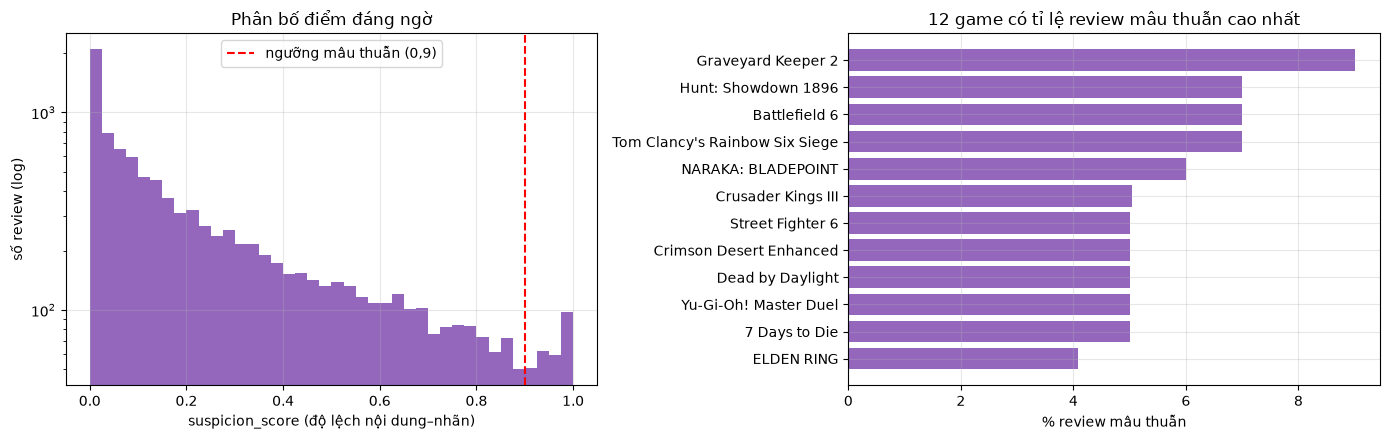

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(df.suspicion_score, bins=40, color="C4")
axes[0].axvline(.9, c="r", ls="--", label="ngưỡng mâu thuẫn (0,9)")
axes[0].set_yscale("log")
axes[0].set(xlabel="suspicion_score (độ lệch nội dung–nhãn)", ylabel="số review (log)",
            title="Phân bố điểm đáng ngờ")
axes[0].legend()
g = df.groupby("game_name").flag_mismatch.mean().sort_values(ascending=False).head(12) * 100
axes[1].barh(g.index[::-1], g.values[::-1], color="C4")
axes[1].set(xlabel="% review mâu thuẫn", title="12 game có tỉ lệ review mâu thuẫn cao nhất")
fig.tight_layout()
plt.show()

## 5. Bài 3 — Chấm mức hữu ích
**Mục tiêu**: dự đoán review có nhận được **ít nhất 1 vote hữu ích** hay không (`votes_helpful > 0`, 32,5% review).
Chọn dạng có/không thay vì đoán số vote vì 67,5% review có 0 vote và số vote lệch rất mạnh.

**Vấn đề cần kiểm soát — tuổi review**: review càng cũ càng có thời gian nhận vote. Nếu bỏ qua, mô hình sẽ học
"review cũ = hữu ích" thay vì học nội dung. Vì vậy thêm `log_age_days` (số ngày từ lúc viết đến lúc crawl) làm biến
kiểm soát. Ở bài này tuổi review là **biến hợp lệ** (không phải lộ nhãn), khác với bài 1.

Đặc trưng: text + meta của bài 1 + `log_age_days` + nhãn cảm xúc (`label`, vì review negative được vote nhiều hơn).

So sánh: (a) chỉ tuổi review; (b) meta + tuổi; (c) TF-IDF + meta + tuổi; (d) mạng Keras M4 (TF-IDF + Dense) + meta + tuổi.
Dữ liệu lệch lớp (32/68) → dùng `class_weight` cho Keras và metric **ROC-AUC / PR-AUC** (PR-AUC của đoán bừa = 0,325).

Tỉ lệ có vote hữu ích: 0.325


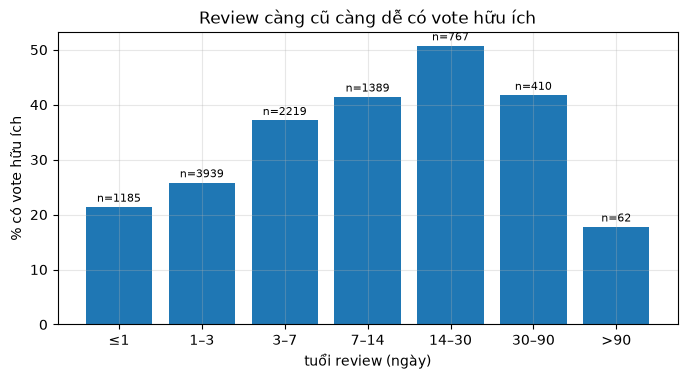

In [20]:
crawl_end = df.timestamp_created.max()
df["log_age_days"] = np.log1p((crawl_end - df.timestamp_created) / 86400)
df["has_helpful"] = (df.votes_helpful > 0).astype(int)
yh = df.has_helpful.values
META_H = META + ["log_age_days", "label"]
print("Tỉ lệ có vote hữu ích:", round(yh.mean(), 3))

fig, ax = plt.subplots(figsize=(8, 3.8))
age_bin = pd.cut(np.expm1(df.log_age_days), [-1, 1, 3, 7, 14, 30, 90, 1e5],
                 labels=["≤1", "1–3", "3–7", "7–14", "14–30", "30–90", ">90"])
r = df.groupby(age_bin, observed=True).has_helpful.agg(["mean", "size"])
ax.bar(r.index.astype(str), r["mean"] * 100, color="C0")
for i, (m, n) in enumerate(r.values):
    ax.text(i, m * 100 + 1, f"n={int(n)}", ha="center", fontsize=8)
ax.set(xlabel="tuổi review (ngày)", ylabel="% có vote hữu ích", title="Review càng cũ càng dễ có vote hữu ích")
plt.show()

Biểu đồ xác nhận: review ≤ 1 ngày tuổi rất ít khi có vote, review > 30 ngày tuổi phần lớn đã có vote.
Chỉ riêng tuổi review đã cho ROC-AUC ≈ 0,62 (bảng dưới) → bắt buộc phải kiểm soát biến này.

In [21]:
tr, va, te = SPLITS["A"]
sc = StandardScaler().fit(df[META_H].values[tr])
MH = {n: sc.transform(df[META_H].values[ix]) for n, ix in [("tr", tr), ("va", va), ("te", te)]}
age_col = META_H.index("log_age_days")

m, _ = fit_lr(MH["tr"][:, [age_col]], yh[tr], MH["va"][:, [age_col]], yh[va])
evaluate("LR — chỉ tuổi review", "A", yh[te], m.predict_proba(MH["te"][:, [age_col]])[:, 1], task="helpful")
m, _ = fit_lr(MH["tr"], yh[tr], MH["va"], yh[va])
evaluate("LR — meta + tuổi", "A", yh[te], m.predict_proba(MH["te"])[:, 1], task="helpful")
coef_h = pd.Series(m.coef_[0], index=META_H).sort_values()

Ttr, (Tva, Tte) = tfidf_features(tr, [va, te])
Xtr, Xva, Xte = (hstack([T, csr_matrix(MH[n])]).tocsr() for T, n in [(Ttr, "tr"), (Tva, "va"), (Tte, "te")])
m, _ = fit_lr(Xtr, yh[tr], Xva, yh[va])
evaluate("TF-IDF + meta + tuổi + LR", "A", yh[te], m.predict_proba(Xte)[:, 1], task="helpful")

tf.keras.utils.set_random_seed(SEED)
mh = build_model("tfidf", vecA_tfidf, len(META_H), df[META_H].values[tr].astype("float32"), name="Helpful_M4")
w = {0: 1.0, 1: (1 - yh[tr].mean()) / yh[tr].mean()}
h_help = train(mh, tr, va, yh, META_H, class_weight=w)
p_help = predict(mh, te, META_H)
evaluate("Keras M4 TF-IDF+Dense + meta + tuổi", "A", yh[te], p_help, task="helpful")

t = pd.DataFrame([r for r in RESULTS if r["bài"] == "helpful"]).drop(columns=["bài", "kịch bản", "accuracy"])
display(t.set_index("mô hình").round(3))

Helpful_M4: 6 epoch, 21s, val_loss tốt nhất 0.634


,F1,ROC-AUC,PR-AUC
mô hình,,,
LR — chỉ tuổi review,0.065,0.624,0.429
LR — meta + tuổi,0.515,0.771,0.601
TF-IDF + meta + tuổi + LR,0.542,0.786,0.636
Keras M4 TF-IDF+Dense + meta + tuổi,0.611,0.761,0.605


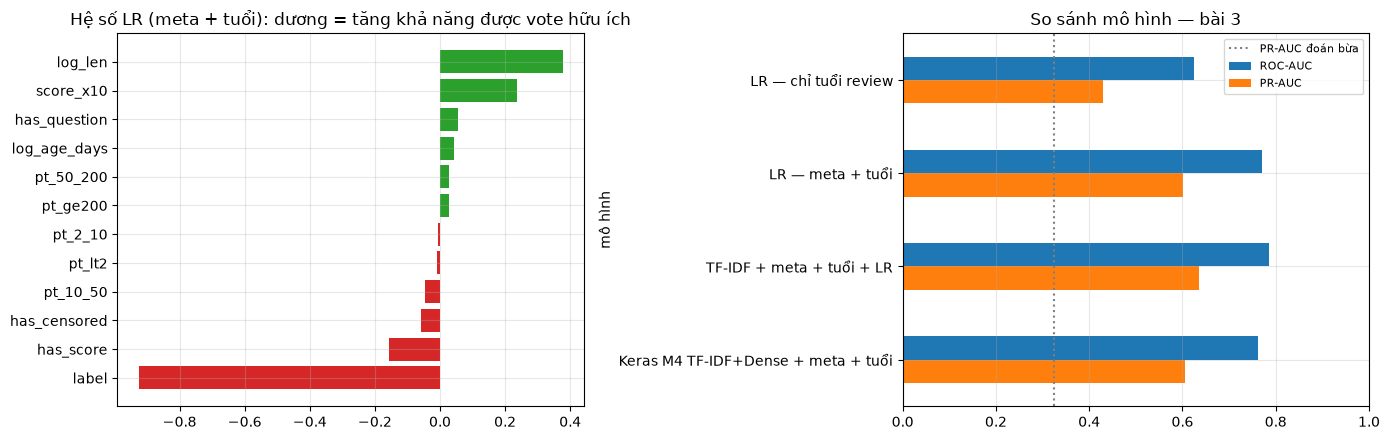

Review mô hình chấm hữu ích cao nhất (test):


,game_name,text_clean,label,votes_helpful,p_helpful
4706,ELDEN RING,"This isn't a good Souls game. Firstly, let's get this out of the way: Souls fans, this review is not for you. You already bought the game, complet...",0,0,1.0
3408,Palworld,"Let me just start off with something very simple. This game is basically, open-world ARK gameplay, mixed with monster collecting, and building mec...",0,2,1.0
850,Slay the Spire 2,"TL;DR: Card bloat, excessive debuffs, simplistic build breaking mob/bosses, simplistic smash head into player filler mob/bosses, action point limi...",0,7,1.0
9742,Crusader Kings III,"You need five minutes just to launch the game, and once you finally get in, it runs like an unstable, resource-hogging mess. And the worst part? T...",0,4,1.0
5073,Yu-Gi-Oh! Master Duel,"alright, I've played this when it came out due to duel links being a terrible game (even for beginners) I've played the steam and mobile clients. ...",0,2,1.0
5109,Yu-Gi-Oh! Master Duel,TL - The game's currency is hostile towards the players (extremely long review about gems and not gameplay in specific) if you want the SUPER shor...,0,5,1.0


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].barh(coef_h.index, coef_h.values, color=np.where(coef_h.values > 0, "C2", "C3"))
axes[0].set_title("Hệ số LR (meta + tuổi): dương = tăng khả năng được vote hữu ích")
t.set_index("mô hình")[["ROC-AUC", "PR-AUC"]].plot.barh(ax=axes[1])
axes[1].axvline(yh.mean(), c="gray", ls=":", label="PR-AUC đoán bừa")
axes[1].set_xlim(0, 1)
axes[1].invert_yaxis()
axes[1].set_title("So sánh mô hình — bài 3")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

top = df.iloc[te][["game_name", "text_clean", "label", "votes_helpful"]].assign(p_helpful=p_help.round(3))
print("Review mô hình chấm hữu ích cao nhất (test):")
display(top.nlargest(6, "p_helpful"))

**Nhận xét (bài 3)**
- Chỉ tuổi review: ROC-AUC 0,62. Thêm meta (độ dài, nhãn cảm xúc…) lên 0,77; thêm text (TF-IDF) lên **0,79**.
  → Nội dung và độ dài review **có** giúp dự đoán hữu ích, ngoài yếu tố thời gian.
- Mạng Keras M4 đạt ROC-AUC 0,76 nhưng **F1 cao nhất (0,61)** vì train có `class_weight` (ưu tiên bắt review hữu ích);
  LR cao hơn về ROC-AUC. Hai mô hình gần nhau.
- Hệ số LR (biểu đồ trái): yếu tố mạnh nhất là **nhãn** — review **negative** dễ được vote hữu ích hơn hẳn; tiếp theo là review **dài hơn**. Review có từ tục bị che thì ít được vote.
- Review được chấm hữu ích cao nhất đều là review **dài, có phân tích cụ thể** (TL;DR, liệt kê ưu nhược) — hợp lý với
  trực giác "review hữu ích".
- **Hạn chế**: nhãn chỉ là "có ≥ 1 vote", nhiều review mới chưa kịp được vote → nhãn nhiễu; kết quả mức khá (ROC-AUC ~0,78),
  không nên kỳ vọng như bài 1. Lưu ý thêm: do cách crawl (lấy review mới nhất), negative thường cũ hơn → một phần quan hệ
  negative–hữu ích có thể đến từ tuổi review.

## 6. Lưu mô hình
Lưu mạng Keras tốt nhất của bài 1 (kịch bản A), mô hình bài 3 và bảng điểm đáng ngờ của bài 2 để dùng lại / demo.
File `.keras` chứa cả lớp `TextVectorization`, nên có thể đưa thẳng chuỗi text vào để dự đoán.

In [23]:
os.makedirs("models", exist_ok=True)
MODELS_A[best_keras].save("models/sentiment_best.keras")
mh.save("models/helpful_m4.keras")
df[["review_id", "game_name", "text_clean", "label", "p_pos_oof", "suspicion_score", "flag_mismatch",
    "suspicious"] + FLAG_COLS].to_csv("data/steam_reviews_suspicious.csv", index=False, encoding="utf-8")
print("Đã lưu models/sentiment_best.keras, models/helpful_m4.keras, data/steam_reviews_suspicious.csv")

demo = ["Best game ever, 10/10 would play again", "Crashes every 5 minutes. Refunded.",
        "Oh great, another update that breaks everything. Love it.", "not bad at all"]
loaded = tf.keras.models.load_model("models/sentiment_best.keras")
use_meta = len(loaded.inputs) > 1
dm = pd.DataFrame({"text_clean": demo})
dm["log_len"] = np.log1p(dm.text_clean.str.split().str.len())
dm["score_x10"] = dm.text_clean.map(first_score)
dm["has_score"] = dm.score_x10.notna().astype(int)
dm["score_x10"] = dm.score_x10.fillna(0)
dm["has_question"] = dm.text_clean.str.contains("?", regex=False).astype(int)
dm["has_censored"] = 0
for c in PT_LABELS:
    dm[c] = int(c == "pt_10_50")      # giả định giờ chơi 10–50h
inp = {"text": tf.constant(demo)}
if use_meta:
    inp["meta"] = dm[META].values.astype("float32")
dm["p_positive"] = loaded.predict(inp, verbose=0).ravel().round(3)
display(dm[["text_clean", "p_positive"]])

Đã lưu models/sentiment_best.keras, models/helpful_m4.keras, data/steam_reviews_suspicious.csv


,text_clean,p_positive
0,"Best game ever, 10/10 would play again",0.996
1,Crashes every 5 minutes. Refunded.,0.233
2,"Oh great, another update that breaks everything. Love it.",0.769
3,not bad at all,0.683


**Thử mô hình với câu tự viết** (giả định giờ chơi 10–50h):
- "Best game ever, 10/10" → gần 1; "Crashes every 5 minutes. Refunded." → thấp: đúng.
- "Oh great, another update that breaks everything. Love it." (mỉa mai) → mô hình vẫn đoán **positive** vì có "great",
  "love" → minh hoạ điểm yếu: **mỉa mai rất khó** với mô hình dựa trên từ. Đây là lý do cần bài 2.
- "not bad at all" → ≈ 0,68: đúng hướng nhưng chưa chắc, vì "bad" kéo xuống.

## 7. Tổng kết

### Kết quả chính

| bài | mô hình tốt nhất | kết quả (test) | ý nghĩa |
|---|---|---|---|
| 1. Cảm xúc | **M5 Ensemble (BiLSTM + TF-IDF Dense)** — Keras | accuracy 0,82–0,83, ROC-AUC 0,90–0,91 | ngang baseline TF-IDF + LR (0,91); giữ nguyên khi áp sang game mới |
| 2. Review đáng ngờ | luật + mâu thuẫn với M4 | 290 review (2,9%) bị gắn cờ | bắt được review mỉa mai, troll, bấm nhầm, hỗn hợp |
| 3. Hữu ích | TF-IDF + meta + tuổi (LR) / Keras M4 | ROC-AUC 0,79 / 0,76 | text giúp dự đoán thêm ngoài tuổi review; mức khá |

### Kết luận để trình bày
1. **Text là nguồn thông tin chính**: chỉ meta đạt 0,71, có text lên 0,90.
2. **Mạng neural tự học embedding (M1–M3) không vượt baseline** trên ~10k review vì dữ liệu nhỏ, overfit nhanh.
   Kết hợp 2 mạng (ensemble) mới bằng baseline. Muốn vượt rõ cần mô hình train sẵn (BERT) hoặc nhiều dữ liệu hơn.
3. **Mô hình khái quát sang game mới** (kịch bản B ≈ A) → dùng được cho game không có trong dữ liệu train.
4. **Lỗi còn lại phần lớn là review khó**: mỉa mai, khen-chê lẫn lộn, câu quá ngắn → bài 2 tận dụng chính các lỗi này
   để phát hiện review đáng ngờ.
5. **Mức hữu ích** dự đoán được ở mức khá; phải kiểm soát tuổi review, nếu không mô hình chỉ học "review cũ = nhiều vote".

### Các file đầu ra
- `models/sentiment_best.keras`: mạng Keras đơn tốt nhất bài 1 (nhận chuỗi text + 10 đặc trưng meta).
- `models/helpful_m4.keras`: mô hình bài 3.
- `data/steam_reviews_suspicious.csv`: mọi review kèm xác suất out-of-fold, `suspicion_score`, cờ mâu thuẫn.

### Câu hỏi thầy có thể hỏi — gợi ý trả lời

**Vì sao không dùng `votes_helpful`, `timestamp_created` cho bài 1, dù tương quan mạnh nhất?**
Do cách crawl: mỗi game lấy 50 review positive + 50 negative mới nhất. Negative hiếm hơn nên phải lùi về quá khứ xa hơn
→ review cũ (và có nhiều vote hơn) hầu hết là negative. Dùng hai cột này là mô hình học **cách crawl**, không học nội dung;
áp sang dữ liệu thật sẽ sai. Đây gọi là *data leakage*.

**Vì sao có kịch bản B?** Để chứng minh mô hình không học thuộc từ riêng của từng game. Test B gồm 20 game hoàn toàn
không có trong train; kết quả không giảm → mô hình học được cách người chơi khen/chê nói chung.

**Vì sao LSTM không tốt hơn Logistic Regression?** Dữ liệu nhỏ (~7k train). LSTM có 1,35 triệu tham số, học embedding
từ đầu → overfit sau 2–3 epoch (xem đường học). TF-IDF + LR ít tham số tự do hơn nên ổn định. Có dùng Dropout +
EarlyStopping để giảm overfit.

**EarlyStopping / Dropout là gì?** EarlyStopping dừng train khi loss validation không giảm sau 2 epoch và lấy lại trọng
số tốt nhất. Dropout tắt ngẫu nhiên 40% nơ-ron mỗi bước train để mạng không phụ thuộc vào vài nơ-ron → chống overfit.

**Tại sao dùng ROC-AUC chứ không chỉ accuracy?** Accuracy phụ thuộc ngưỡng 0,5; ROC-AUC đo khả năng xếp hạng ở mọi ngưỡng.
Bài 1 nhãn cân bằng nên accuracy vẫn có ý nghĩa; bài 3 lệch lớp (32/68) nên dùng ROC-AUC và PR-AUC.

**Bài 2 không có nhãn thì đánh giá kiểu gì?** Không tính được accuracy. Đánh giá bằng đọc mẫu: các review bị gắn cờ mâu
thuẫn phần lớn đúng là mỉa mai / hỗn hợp / bấm nhầm (ví dụ ở §4). Đây là phương pháp bán giám sát, nói rõ là hạn chế.

**Mô hình xử lý mỉa mai thế nào?** Mô hình bài 1 **không** hiểu mỉa mai (câu demo "Oh great… Love it" bị đoán positive).
Bài 2 tận dụng điều đó: khi nội dung (theo mô hình) và nhãn người viết bấm trái ngược mạnh → nghi mỉa mai.

**Out-of-fold là gì?** Chia dữ liệu 5 phần; mỗi lần train trên 4 phần và dự đoán phần còn lại. Như vậy mọi review đều có
dự đoán từ một mô hình **chưa từng thấy** review đó, tránh việc mô hình "nhớ" nhãn.

**Hướng phát triển**: fine-tune mô hình train sẵn (DistilBERT) trên GPU; crawl thêm `votes_funny` để phát hiện troll trực
tiếp; tăng số review mỗi game; lấy `playtime_at_review` thay cho tổng giờ chơi hiện tại.